# Magnetic quantities, frame and provenance

**Level 1 · Prerequisites: none; reading time: 30 minutes.**

## Objectives

Distinguish the total inducing field from the secondary anomaly, record the ENU frame and units, and inspect source lineage before interpreting a magnetic survey.

## Setup

Use the repository's reviewed Python 3.12 notebook environment. This notebook installs nothing. The committed protocol fixture declares a uniform reference field and a zero-valued serialized payload. It is not measured magnetic response and must not be plotted or interpreted as a field survey.

The following cell inspects the real serialized protocol object and reports its geometry contract.

In [1]:
import runpy
from pathlib import Path

# Read the authored protocol fixture; its zero payload is not a physical measurement.
root = Path.cwd().parents[2]
support = runpy.run_path(str(root / 'tests/data/magnetic_survey_support.py'))
request = support['request']()
acq = request['acquisition']
geom = request['geometry']
print({'source_kind': request['source']['kind'], 'axes': request['frame']['axes'],
       'coordinate_unit': request['frame']['coordinate_unit'],
       'observation_quantity': request['observations']['quantity'],
       'observation_unit': request['observations']['unit'],
       'payload_shape': request['observations']['values']['shape'],
       'inducing_field_nT': request['inducing_field']['F_nT'],
       'flight_groups': len(set(acq['group_ids'])), 'geometry_fields': sorted(geom)})

{'source_kind': 'authored_synthetic', 'axes': 'ENU', 'coordinate_unit': 'm', 'observation_quantity': 'secondary_enu_nT', 'observation_unit': 'nT', 'payload_shape': [288, 3], 'inducing_field_nT': 50000.0, 'flight_groups': 12, 'geometry_fields': ['mesh', 'partition', 'qc_reason', 'receivers_m', 'usable']}


## Data

The committed protocol fixture declares a uniform reference field and a zero-valued serialized payload. It is not measured magnetic response and must not be plotted or interpreted as a field survey.

**Files:** `tests/data/magnetic_survey_support.py`, `tests/fixtures/magnetic_survey/generate.py`.

## Method

In an ENU frame, x=east, y=north, z=up. The inducing vector is B₀=F(cos I sin D, cos I cos D, −sin I), with declination D clockwise from north and inclination I positive downward. For a weak secondary field b, linear total-field anomaly is approximately f·b; exact magnitude |B₀+b|−F can differ. This distinction follows the potential-field modeling context ([Cockett et al., 2015](https://doi.org/10.1016/j.cageo.2015.09.015)); it does not make an authored zero payload observational evidence.

The fixture fixes local ENU axes, metre coordinates, row IDs and a uniform reference field. Given I positive down and D clockwise from north, f=(cos I sin D, cos I cos D, −sin I); the east component is therefore controlled by declination, while the vertical component is negative for positive-down inclination. B₀=Ff has nT components. For secondary vector b, projection f·b produces the first-order total-field anomaly; the exact magnitude |B₀+b|−F includes curvature terms of order |b|²/F. These quantities share nT units but represent different observables.

Before any field interpretation, establish whether b is a measured residual, a processed product or a synthetic control; record background model/epoch, coordinate frame, units, correction lineage and rights. Here all 288 rows are authored geometry, the inducing field is an explicit uniform assumption and the serialized response is zero. The figure displays receiver altitude and the declared field-vector components only. It must not be read as an anomaly map, IGRF estimate or evidence of zero magnetization.

## Results

The cell reports schema provenance, frame, units and array shape, not anomaly amplitude or inversion quality. The protocol payload contains no measured response.

Plot the protocol’s coordinates in metres and the declared uniform field in nT. Since the response payload is identically zero by construction, no magnetic-response field or inversion result is shown.


ENU unit-vector norm: 0.9999999999999999 response payload max abs [nT]: 0.0


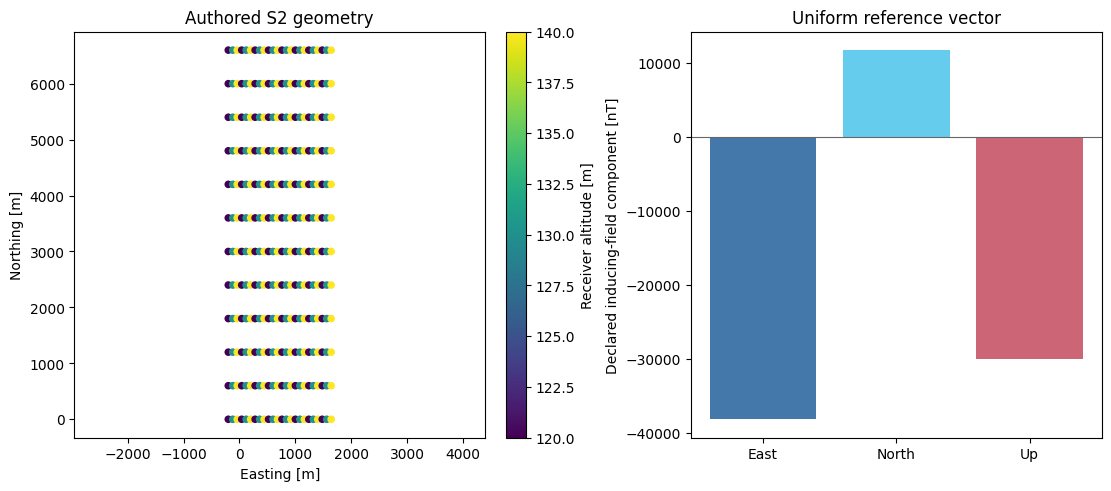

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Plot authored line geometry and the declared field vector; do not interpret the null protocol payload as data.
xyz=np.asarray(geom['receivers_m']['data'],dtype=float).reshape(-1,3); fld=request['inducing_field']
i,d=np.deg2rad([fld['I_deg'],fld['D_deg']]); f=np.array([np.cos(i)*np.sin(d),np.cos(i)*np.cos(d),-np.sin(i)]); B0=fld['F_nT']*f
fig,(ax,bx)=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)
sc=ax.scatter(xyz[:,0],xyz[:,1],c=xyz[:,2],cmap='viridis',s=20)
ax.set(xlabel='Easting [m]',ylabel='Northing [m]',title='Authored S2 geometry'); ax.set_aspect('equal',adjustable='datalim'); fig.colorbar(sc,ax=ax,label='Receiver altitude [m]')
bx.bar(['East','North','Up'],B0,color=['#4477aa','#66ccee','#cc6677']); bx.axhline(0,color='.4',lw=.8)
bx.set(ylabel='Declared inducing-field component [nT]',title='Uniform reference vector')
print('ENU unit-vector norm:',np.linalg.norm(f),'response payload max abs [nT]:',max(abs(x) for x in request['observations']['values']['data']))
plt.show()


## Summary

Keep frame, field convention, source rights and observation provenance attached to every magnetic product.


## References

- https://doi.org/10.1016/j.cageo.2015.09.015